# test evaluation: final test evaluation
The model, probabilities and thresholds were frozen before the test opening. This notebook reads only generated aggregate tables and figures; it never loads records or scores a model.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
root = Path.cwd() if (Path.cwd() / 'AGENTS.md').exists() else Path.cwd().parent
tables, figures = root / 'reports' / 'tables', root / 'reports' / 'figures'

## Frozen thresholds and baseline
The validation thresholds were selected on validation labels, so their validation scores are optimistic. Test metrics assess those fixed thresholds.

In [2]:
display(pd.read_csv(tables / 'test_metrics.csv'))
display(pd.read_csv(tables / 'validation_test_comparison.csv'))
display(pd.read_csv(tables / 'test_risk_bands.csv'))

,model_threshold,threshold,n,positives,prevalence,f1,precision,recall,pr_auc,roc_auc,accuracy,lift_10,lift_20,tn,fp,fn,tp
0,HGB F1,0.182931,3999,508,0.127032,0.360348,0.273096,0.529528,0.303126,0.752027,0.761190,2.814257,2.273054,2775,716,239,269
1,HGB screening,0.154107,3999,508,0.127032,0.354051,0.246522,0.627953,0.303126,0.752027,0.708927,2.814257,2.273054,2516,975,189,319
2,Stratified Dummy,0.500000,3999,508,0.127032,0.123383,0.124748,0.122047,0.126753,0.498721,0.779695,0.865925,1.023366,3056,435,446,62


,split,model_threshold,f1,precision,recall,pr_auc,roc_auc,prevalence,lift_10,note
0,validation,HGB F1,0.353569,0.267137,0.522682,0.312313,0.744595,0.126845,2.641016,threshold chosen on validation labels
1,validation,HGB screening,0.348372,0.245177,0.601578,0.312313,0.744595,0.126845,2.641016,threshold chosen on validation labels
2,validation,Stratified Dummy,0.123506,0.124748,0.122288,0.126589,0.498823,0.126845,0.965745,training-fitted dummy
3,test,HGB F1,0.360348,0.273096,0.529528,0.303126,0.752027,0.127032,2.814257,frozen before test
4,test,HGB screening,0.354051,0.246522,0.627953,0.303126,0.752027,0.127032,2.814257,frozen before test
5,test,Stratified Dummy,0.123383,0.124748,0.122047,0.126753,0.498721,0.127032,0.865925,frozen before test


,risk_band,n,positives,prevalence
0,Elevated,813,158,0.194342
1,High,433,151,0.348730
2,Lower,2753,199,0.072285


## Household-grouped uncertainty
Each of 1,000 bootstrap samples draws households with replacement. Intervals describe variation in these resamples and do not account for the full survey design.

In [3]:
display(pd.read_csv(tables / 'test_bootstrap_ci.csv'))

,model_threshold,metric,lower_95,upper_95,valid_repeats,repeats
0,HGB F1,f1,0.328008,0.392653,1000,1000
1,HGB F1,precision,0.245457,0.302686,1000,1000
2,HGB F1,recall,0.484955,0.576474,1000,1000
3,HGB F1,pr_auc,0.267173,0.342796,1000,1000
4,HGB F1,roc_auc,0.731184,0.774033,1000,1000
5,HGB F1,lift_10,2.450289,3.128584,1000,1000
6,HGB screening,f1,0.325577,0.382092,1000,1000
7,HGB screening,precision,0.222899,0.271122,1000,1000
8,HGB screening,recall,0.584492,0.674749,1000,1000
9,HGB screening,pr_auc,0.267173,0.342796,1000,1000


## Subgroups and errors
Rows with fewer than 50 unemployed people are flagged as unreliable. Error distributions are counts, not adjusted comparisons.

In [4]:
display(pd.read_csv(tables / 'test_subgroups.csv'))
errors = pd.read_csv(tables / 'test_error_distributions.csv')
display(errors.loc[errors.feature.isin(['age', 'sex', 'area', 'education_level'])])

,subgroup,value,threshold,n,positives,unreliable_fewer_than_50_positives,flag_rate,precision,recall
0,sex,Female,f1,909,125,False,0.268427,0.348361,0.680000
1,sex,Female,screening,909,125,False,0.295930,0.338290,0.728000
2,sex,Male,f1,3090,383,False,0.239806,0.248313,0.480418
3,sex,Male,screening,3090,383,False,0.331715,0.222439,0.595300
4,area,Rural,f1,2840,321,False,0.198592,0.283688,0.498442
5,area,Rural,screening,2840,321,False,0.271479,0.243839,0.585670
6,area,Urban,f1,1159,187,False,0.363244,0.258907,0.582888
7,area,Urban,screening,1159,187,False,0.451251,0.250478,0.700535
8,sex_area,Female / Rural,f1,712,73,False,0.175562,0.320000,0.547945
9,sex_area,Female / Rural,screening,712,73,False,0.202247,0.305556,0.602740


,outcome,feature,value,count
0,FN,age,15.0,12
1,FN,age,16.0,20
2,FN,age,17.0,16
3,FN,age,18.0,36
4,FN,age,19.0,16
...,...,...,...,...
420,FP,area,2.0,312
421,TN,area,1.0,2115
422,TN,area,2.0,660
423,TP,area,1.0,160


## Ranking, classification and calibration

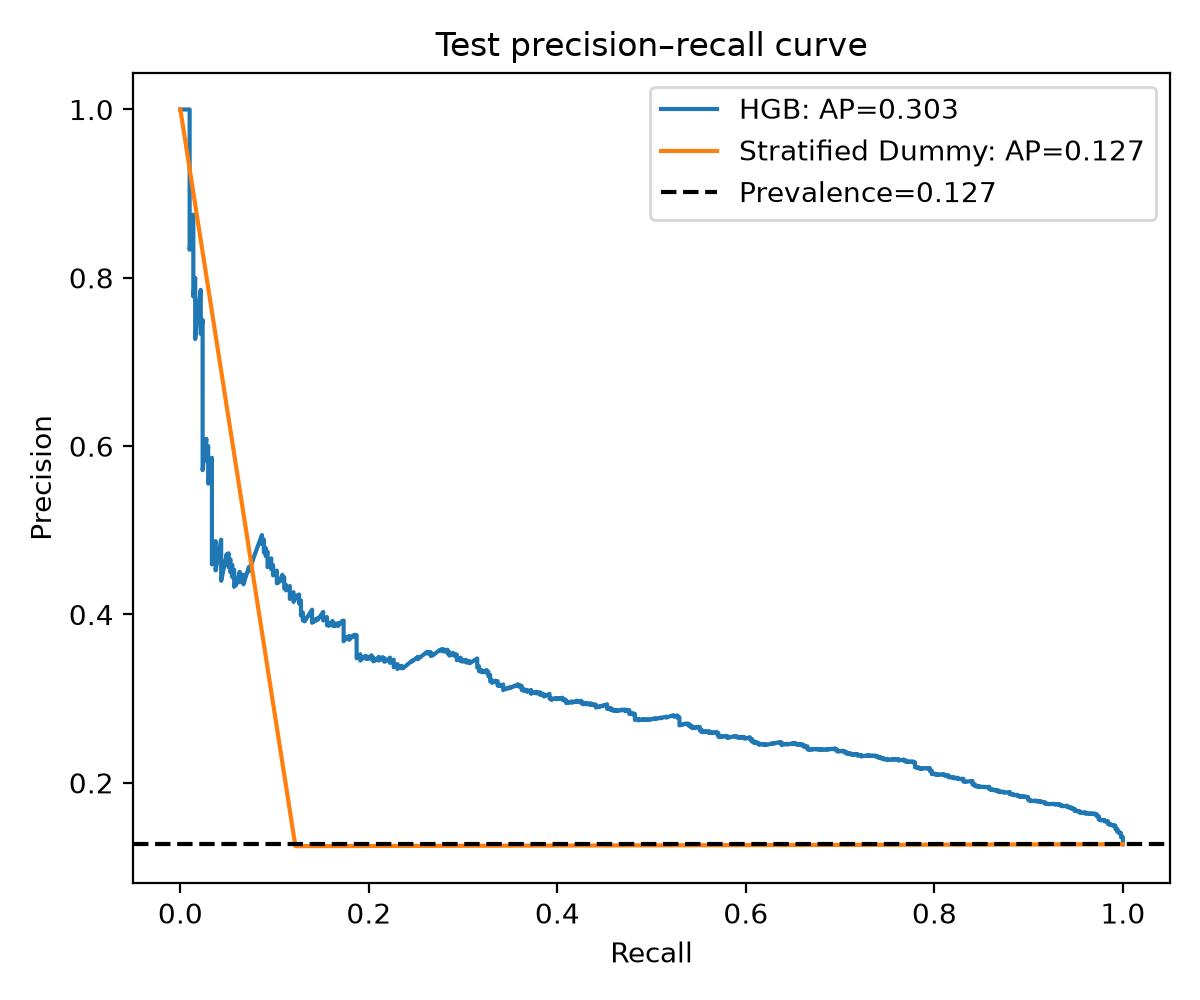

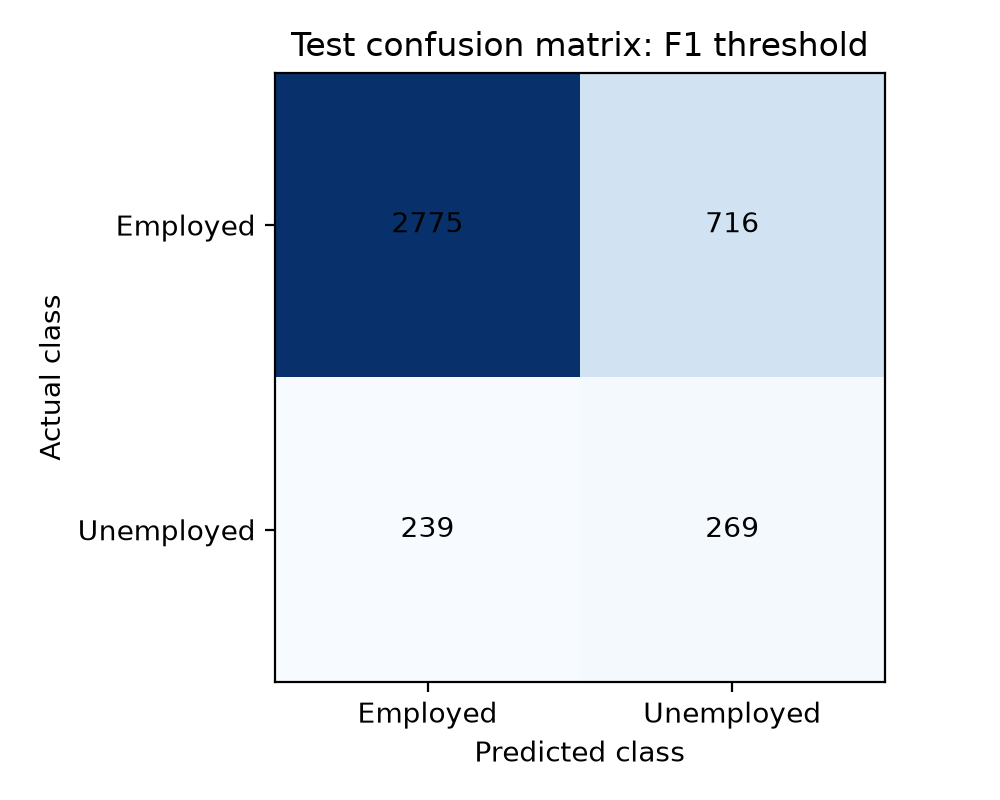

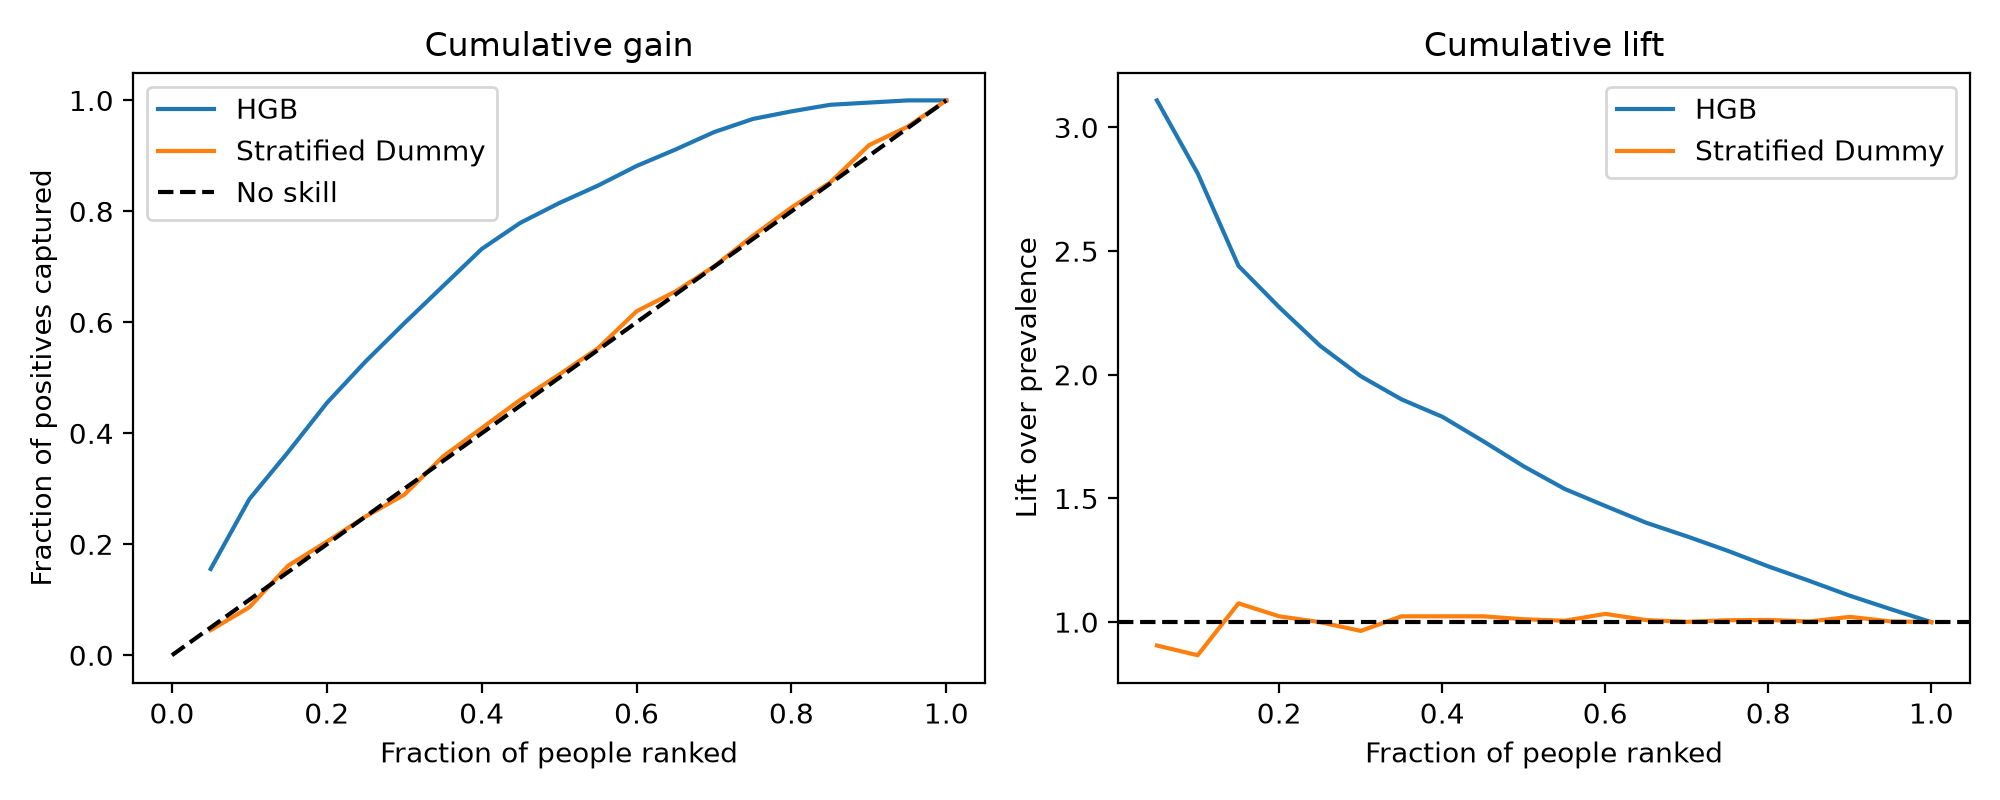

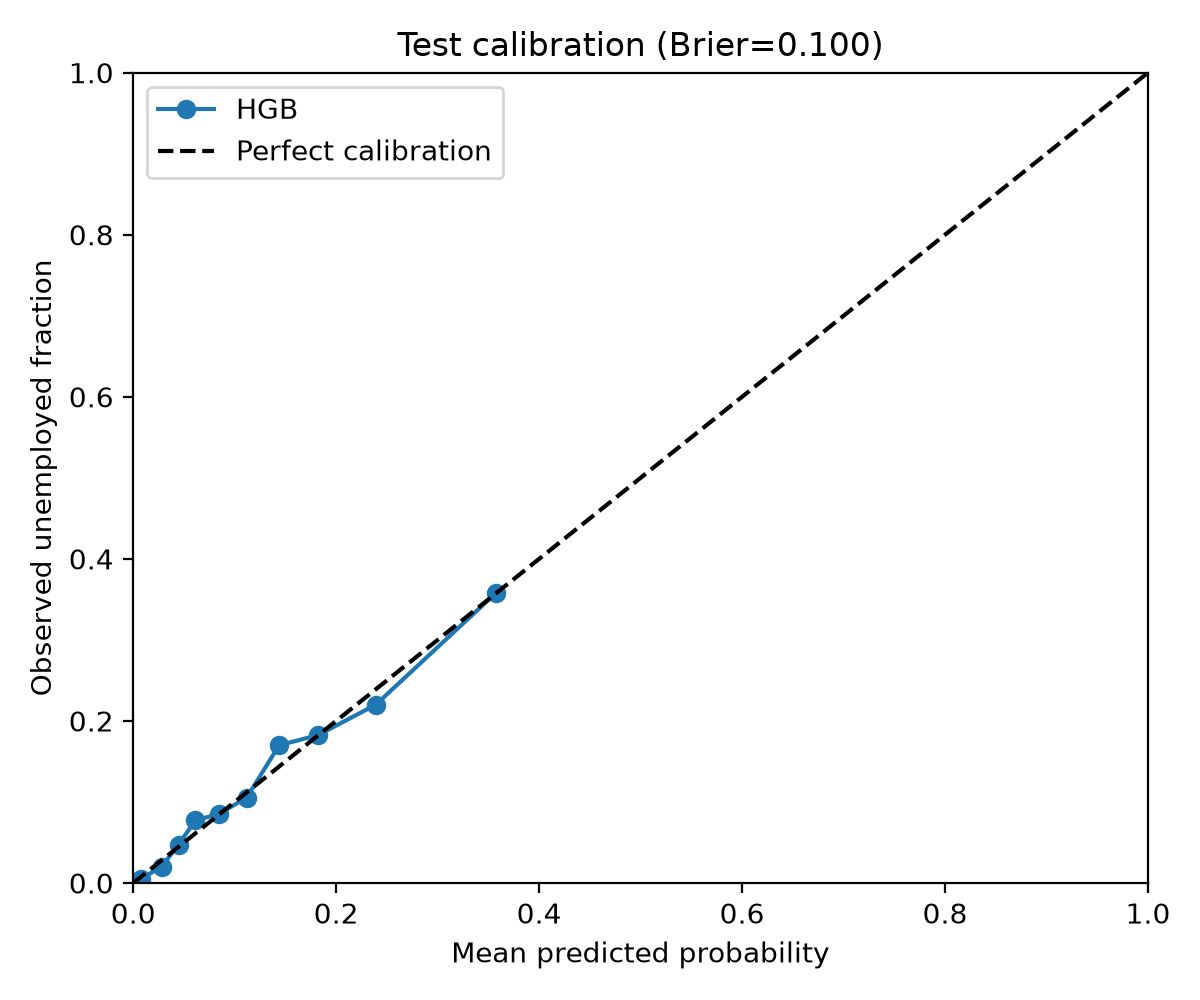

In [5]:
for name in ['test_pr_curve.png', 'test_confusion_matrix.png', 'test_gain_lift.png', 'test_calibration.png']:
    display(Image(filename=str(figures / name)))

## Interpretation
See `docs/test_findings.md` for the baseline comparison, subgroup limitations and appropriate use. The saved test probabilities remain private and are not displayed here.